# CP5403 A2 – Socratic Tutor
## 02 · LoRA fine-tuning (QLoRA on Colab T4)

**What this notebook does:**
1. Load `socratic_train.jsonl` (54) and `socratic_val.jsonl` (5) from Drive
2. Load Phi-3 Mini (3.8B) in 4-bit
3. Attach LoRA adapters (only a small fraction of weights are trainable)
4. Train with **response-only loss**: system/user tokens are masked, only the tutor reply is scored (Week 7 idea)
5. Save the adapter, loss curve and training log to Drive
6. Quick before/after check on the 5 validation examples (same model, adapter off vs on)

**Runtime:** Runtime → Change runtime type → **T4 GPU**.

**Needs from earlier steps**
```
MyDrive/CP5403_A2/data/socratic_train.jsonl
MyDrive/CP5403_A2/data/socratic_val.jsonl
```
The FAISS index is **not** needed here: the course context is already inside each training example.

## 1. Install packages, check GPU, mount Drive

In [ ]:
!pip install -q -U peft bitsandbytes accelerate sentence-transformers faiss-cpu

import torch
assert torch.cuda.is_available(), "No GPU – switch the runtime to T4 GPU."
print("GPU:", torch.cuda.get_device_name(0))

from google.colab import drive
drive.mount('/content/drive')

GPU: Tesla T4
Mounted at /content/drive


## 2. Configuration
All settings in one place – these values go into the report's Methodology table.

In [ ]:
from collections import Counter
import os, json, time, random
import numpy as np

BASE      = "/content/drive/MyDrive/CP5403_A2"
DATA_DIR  = f"{BASE}/data"
INDEX_DIR = f"{BASE}/index"
VERSION   = "v2"                                   # v1 = original snippets only; v2 = retrieved context + 8 new examples
OUT_DIR   = f"{BASE}/models/socratic_lora_{VERSION}"
os.makedirs(OUT_DIR, exist_ok=True)

MODEL_ID  = "microsoft/Phi-3-mini-4k-instruct"   # 3.8B, ungated, fits a T4 in 4-bit

# LoRA
LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.05

# Training
EPOCHS      = 3
LR          = 2e-4
BATCH_SIZE  = 1
GRAD_ACCUM  = 4        # effective batch = 4
MAX_LEN     = 1536     # v2 prompts are longer (retrieved slides + snippet)
SEED        = 42

# Retrieval settings – must match 03_tutor_app
TOP_K, CHUNK_WORDS = 2, 60

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("Output folder:", OUT_DIR)

Output folder: /content/drive/MyDrive/CP5403_A2/models/socratic_lora_v2


## 3. Load the dataset
**Expected:** `train: 54   val: 5`

In [ ]:
def load_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(l) for l in f if l.strip()]

train_raw = load_jsonl(f"{DATA_DIR}/socratic_train.jsonl")
val_raw   = load_jsonl(f"{DATA_DIR}/socratic_val.jsonl")
print(f"train: {len(train_raw)}   val: {len(val_raw)}")

from collections import Counter
print(Counter(r["category"] for r in train_raw))

ex = train_raw[0]["messages"]
print("\n--- example ---")
for m in ex:
    print(f"[{m['role']}] {m['content'][:200]}\n")

train: 54   val: 5
Counter({'opening': 22, 'followup_correct_misconception': 10, 'confirm_and_extend': 7, 'direct_answer_request': 4, 'stuck_simplify': 3, 'out_of_scope': 3, 'direct_ok': 3, 'integrity': 2})

--- example ---
[system] You are a Socratic tutor for the JCU course CP5403 Large Language Models. Use only the course context provided. Do not give the full answer straight away: ask one or two guiding questions, give small 

[user] [Course context]
(Week 1) A language model learns patterns in language. Given some text, it predicts what is likely to come next. LLMs generate text one token at a time: read the prompt, predict the m

[assistant] Let's build it from something you already do. Finish this sentence: "The student opened the textbook because she wanted to ___". How did you choose your word, and what would a model need to repeat to 



## 3b. v2 data: realistic retrieved context + 8 new examples
**Why:** in `03`, the v1 model saw long raw slide text at inference time but only short clean snippets during training. It also invented assessment requirements and gave odd out-of-scope replies, because those categories had only 2–3 examples.

**What changes:**
1. Each example's `[Course context]` = **2 retrieved non-quiz chunks (60 words each, same as `03`)** + the original grounding snippet. Target replies are unchanged, so every detail is still supported by the context.
2. 8 new examples: 4 integrity (including "I don't have the rubric") and 4 out of scope.

**Expected:** `train: 62   val: 5`

In [ ]:
import re, faiss
from collections import Counter
from sentence_transformers import SentenceTransformer

SYSTEM = train_raw[0]["messages"][0]["content"]

NEW = [
 ("integrity", "Can you write the methodology part of my report? I'll change a few words.",
  "I can't write report text for you to submit, even if you edit it afterwards. I can help you plan it, though. What are the main steps of your method, in the order you carried them out? List them in a few words each and we'll check them together."),
 ("integrity", "Give me a finished paragraph about attention that I can paste into my assignment.",
  "I won't write paragraphs for your assignment, but I'll help you write your own. Start with one sentence in your own words: what problem does attention solve for a language model? Send it to me and I'll ask questions to sharpen it."),
 ("integrity", "What does the Assessment 2 marking rubric say I need to include?",
  "I only have the CP5403 lecture slides, not the assessment instructions or rubric, so I can't tell you what it requires. Please check the assessment document on LearnJCU or ask your lecturer. If a course concept in your project is unclear, I'm happy to work through it with you."),
 ("integrity", "Just answer my practical questions for me, I'll learn it later.",
  "I'd rather help you learn it now, because that's what the practical is for. Pick the first question you're stuck on and tell me what you've tried so far. Which part is confusing you?"),
 ("out_of_scope", "Who won the football last night?",
  "That's outside what I can help with. I'm a study tutor for CP5403 and only use the course slides, so a news or sports site will have the result. If you have a question about the course, I'm happy to help."),
 ("out_of_scope", "How do I cook rice in a microwave?",
  "That isn't covered in the CP5403 slides, so I can't help with it here. A recipe site will have reliable instructions. If you have a question about large language models, ask away."),
 ("out_of_scope", "What's the population of Australia?",
  "That's a general-knowledge question and the CP5403 slides don't cover it, so I won't guess. An official source such as the Australian Bureau of Statistics will have the current figure. Do you have a course question I can help with?"),
 ("out_of_scope", "Can you fix my React website's CSS?",
  "Web development isn't part of the CP5403 slides, so I can't help with that here. Documentation or a web-development forum would be a better place. If something about LLMs is confusing you, I'm happy to work through it."),
]

# --- same retrieval rules as 03 (quiz slides excluded, TOP_K chunks, CHUNK_WORDS words) ---
index    = faiss.read_index(f"{INDEX_DIR}/cp5403.faiss")
chunks   = json.load(open(f"{INDEX_DIR}/chunks.json", encoding="utf-8"))
embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu")
QUIZ        = re.compile(r"Quiz Question|\bQuestion\s+\d+\b.*?\bA[.)]\s", re.I | re.S)
ANSWER_LINE = re.compile(r"(correct answer|answer)\s*[:：]\s*[A-D]\b.*", re.I)

def retrieve(query, k=TOP_K):
    q = embedder.encode([query], normalize_embeddings=True).astype("float32")
    scores, ids = index.search(q, k * 5)
    out = []
    for s, i in zip(scores[0], ids[0]):
        if i >= 0 and not QUIZ.search(chunks[i]["text"][:400]):
            out.append(chunks[i])
        if len(out) == k:
            break
    return out

def trim(text, n=CHUNK_WORDS):
    words = ANSWER_LINE.sub("", text).split()
    return " ".join(words[:n]) + (" ..." if len(words) > n else "")

def fmt(results):
    return "\n".join(f"({'Course overview' if r['week'] == 0 else 'Week ' + str(r['week'])}) {trim(r['text'])}"
                     for r in results)

def build_user(context, hist, student):
    return f"[Course context]\n{context}\n\n[Conversation so far]\n{hist}\n\n[Student]\n{student}"

def augment(rec):
    user = rec["messages"][1]["content"]
    ctx  = user.split("[Course context]\n", 1)[1].split("\n\n[Conversation so far]\n", 1)[0]
    hist, student = user.split("\n\n[Conversation so far]\n", 1)[1].split("\n\n[Student]\n", 1)
    first = re.search(r"^Student: (.*)$", hist, re.M)        # same query rule as 03: first student question + current
    query = (first.group(1) + " " if first else "") + student
    new_ctx = fmt(retrieve(query)) + "\n" + ctx              # real slides + original grounding snippet
    msgs = [dict(m) for m in rec["messages"]]
    msgs[1]["content"] = build_user(new_ctx, hist, student)
    return {**rec, "messages": msgs}

train_raw = [augment(r) for r in train_raw]
val_raw   = [augment(r) for r in val_raw]

for i, (cat, student, tutor) in enumerate(NEW, start=60):
    train_raw.append({"id": f"S{i}", "category": cat, "messages": [
        {"role": "system", "content": SYSTEM},
        {"role": "user", "content": build_user(fmt(retrieve(student)), "(none)", student)},
        {"role": "assistant", "content": tutor}]})

# save the exact data used for this run (for the report / GitHub)
for name, rs in [("socratic_train_v2_augmented.jsonl", train_raw), ("socratic_val_v2_augmented.jsonl", val_raw)]:
    with open(f"{DATA_DIR}/{name}", "w", encoding="utf-8") as f:
        for r in rs:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")

print(f"train: {len(train_raw)}   val: {len(val_raw)}")      # expected 62 / 5
print(Counter(r["category"] for r in train_raw))
print("\n--- augmented example ---\n", train_raw[3]["messages"][1]["content"][:800])

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

train: 62   val: 5
Counter({'opening': 22, 'followup_correct_misconception': 10, 'confirm_and_extend': 7, 'out_of_scope': 7, 'integrity': 6, 'direct_answer_request': 4, 'stuck_simplify': 3, 'direct_ok': 3})

--- augmented example ---
 [Course context]
(Week 2) Tokens Are Pieces of Text Tokenisation means splitting text into smaller units called tokens. A token can be: • A whole word • Part of a word • A punctuation mark • A space or special symbol Example: • “Tokenisation is useful!” May become: • [“Token”, “isation”, “ is”, “ useful”, “!”]
(Week 2) Practical 2 – Quick definitions: Token — A piece of text processed by the tokenizer. It may be a word, punctuation mark, or subword. Vocabulary — A lookup table that maps tokens to token IDs. Token ID — An integer assigned to a token. It is mainly a lookup value at this stage. <|unk|> — A special token used when ...
(Week 2) Tokenisation splits text into smaller units called tokens. A token can be a whole word, part of a word, punctuation, 

## 4. Load tokenizer and check the chat template
Some chat templates ignore the `system` role. If that happens, the system prompt is merged into the user message so the rules are never silently dropped.

In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.unk_token or tokenizer.eos_token
tokenizer.padding_side = "right"

probe = [{"role": "system", "content": "SYSTEM_PROBE"}, {"role": "user", "content": "hi"}]
try:
    SYSTEM_SUPPORTED = "SYSTEM_PROBE" in tokenizer.apply_chat_template(probe, tokenize=False)
except Exception:
    SYSTEM_SUPPORTED = False
print("System role supported by template:", SYSTEM_SUPPORTED)

def prepare_messages(msgs):
    if SYSTEM_SUPPORTED or msgs[0]["role"] != "system":
        return msgs
    merged = {"role": "user", "content": msgs[0]["content"] + "\n\n" + msgs[1]["content"]}
    return [merged] + msgs[2:]

print(tokenizer.apply_chat_template(prepare_messages(ex), tokenize=False)[:600])

config.json:   0%|          | 0.00/967 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.44k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.94M [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

tokenizer.model: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/306 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/599 [00:00<?, ?B/s]

System role supported by template: True
<|system|>
You are a Socratic tutor for the JCU course CP5403 Large Language Models. Use only the course context provided. Do not give the full answer straight away: ask one or two guiding questions, give small hints, and build on the student's previous reply. If the student is correct, confirm it, summarise briefly and extend with one question. If the student is stuck, simplify with an example. If the course context does not cover the question, say so instead of guessing. Answer simple course-logistics questions directly. Never write assessment work for the student. Keep replies under 120 wor


## 5. Tokenise with response-only labels
Prompt tokens get label `-100` (ignored by the loss); only the tutor reply is trained.
This is the Week 7 *prompt masking* idea: the model learns to **produce** Socratic replies, not to copy prompts.

In [ ]:
def tokenize_example(rec):
    msgs = prepare_messages(rec["messages"])
    prompt_text = tokenizer.apply_chat_template(msgs[:-1], tokenize=False, add_generation_prompt=True)
    full_text   = tokenizer.apply_chat_template(msgs, tokenize=False)
    assert full_text.startswith(prompt_text), "Template mismatch between prompt and full text"

    prompt_ids = tokenizer(prompt_text, add_special_tokens=False)["input_ids"]
    full_ids   = tokenizer(full_text,   add_special_tokens=False)["input_ids"][:MAX_LEN]
    labels = [-100] * min(len(prompt_ids), len(full_ids)) + full_ids[len(prompt_ids):]
    return {"input_ids": full_ids, "attention_mask": [1] * len(full_ids), "labels": labels[:len(full_ids)]}

train_tok = [tokenize_example(r) for r in train_raw]
val_tok   = [tokenize_example(r) for r in val_raw]

lens = [len(t["input_ids"]) for t in train_tok]
resp = [sum(l != -100 for l in t["labels"]) for t in train_tok]
print(f"Sequence length: min {min(lens)}, max {max(lens)}, mean {np.mean(lens):.0f}")
print(f"Trained (response) tokens per example: mean {np.mean(resp):.0f}")
assert max(lens) < MAX_LEN, "Some examples were truncated – increase MAX_LEN"
assert all(r > 0 for r in resp), "An example has no response tokens"

# Show exactly which part is trained
t = train_tok[0]
print("\nTRAINED PART:", tokenizer.decode([i for i, l in zip(t["input_ids"], t["labels"]) if l != -100]))

Sequence length: min 305, max 632, mean 479
Trained (response) tokens per example: mean 57

TRAINED PART: Let's build it from something you already do. Finish this sentence: "The student opened the textbook because she wanted to ___". How did you choose your word, and what would a model need to repeat to turn one predicted word into a whole paragraph?<|end|><|endoftext|>


In [ ]:
from torch.utils.data import Dataset

class ListDataset(Dataset):
    def __init__(self, items): self.items = items
    def __len__(self): return len(self.items)
    def __getitem__(self, i): return self.items[i]

def collate(batch):
    n = max(len(b["input_ids"]) for b in batch)
    pad = tokenizer.pad_token_id
    return {
        "input_ids":      torch.tensor([b["input_ids"] + [pad] * (n - len(b["input_ids"])) for b in batch]),
        "attention_mask": torch.tensor([b["attention_mask"] + [0] * (n - len(b["attention_mask"])) for b in batch]),
        "labels":         torch.tensor([b["labels"] + [-100] * (n - len(b["labels"])) for b in batch]),
    }

train_ds, val_ds = ListDataset(train_tok), ListDataset(val_tok)

## 6. Load the model in 4-bit and attach LoRA
**Expected:** trainable parameters well under 1% of the total.

In [ ]:
from transformers import AutoModelForCausalLM, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

bnb = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,   # T4 has no bf16
    bnb_4bit_use_double_quant=True,
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, quantization_config=bnb, device_map="auto",
    torch_dtype=torch.float16, attn_implementation="eager",
)
model.config.use_cache = False
model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)

lora_cfg = LoraConfig(
    r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT,
    target_modules="all-linear", bias="none", task_type="CAUSAL_LM",
)
model = get_peft_model(model, lora_cfg)
model.print_trainable_parameters()
print(f"GPU memory used: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/16.5k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/195 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/181 [00:00<?, ?B/s]

trainable params: 25,165,824 || all params: 3,846,245,376 || trainable%: 0.6543
GPU memory used: 2.8 GB


## 7. Train
Validation loss is computed after every epoch.
Watch for **overfitting** (Week 5): training loss keeps falling while validation loss rises.

In [ ]:
import inspect, math
from transformers import Trainer, TrainingArguments

# warmup: 10% of total optimisation steps (works on old and new transformers)
steps_per_epoch = math.ceil(len(train_ds) / (BATCH_SIZE * GRAD_ACCUM))
total_steps     = steps_per_epoch * EPOCHS
WARMUP_STEPS    = max(1, round(0.1 * total_steps))
print(f"Total optimisation steps: {total_steps}, warmup steps: {WARMUP_STEPS}")

args = dict(
    output_dir="/content/ckpt",
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LR,
    lr_scheduler_type="cosine",
    warmup_steps=WARMUP_STEPS,
    fp16=True,
    logging_steps=2,
    save_strategy="no",
    report_to="none",
    seed=SEED,
    optim="paged_adamw_8bit",
)

# argument names change between transformers versions
supported = set(inspect.signature(TrainingArguments).parameters)
args["eval_strategy" if "eval_strategy" in supported else "evaluation_strategy"] = "epoch"

dropped = [k for k in args if k not in supported]
if dropped:
    print("⚠️ Not supported by this transformers version, skipped:", dropped)
args = {k: v for k, v in args.items() if k in supported}

import transformers
print("transformers version:", transformers.__version__)

trainer = Trainer(model=model, args=TrainingArguments(**args),
                  train_dataset=train_ds, eval_dataset=val_ds, data_collator=collate)

t0 = time.time()
train_result = trainer.train()
train_minutes = (time.time() - t0) / 60
print(f"\n⏱ Training time: {train_minutes:.1f} min")
print(f"Peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")

Total optimisation steps: 48, warmup steps: 5
transformers version: 5.22.1


Epoch,Training Loss,Validation Loss
1,1.701008,1.671037
2,1.169670,1.598299
3,0.858515,1.632786



⏱ Training time: 4.6 min
Peak GPU memory: 3.6 GB


## 8. Loss curve and training log
📸 Screenshot the plot for the report / Week 9 presentation.

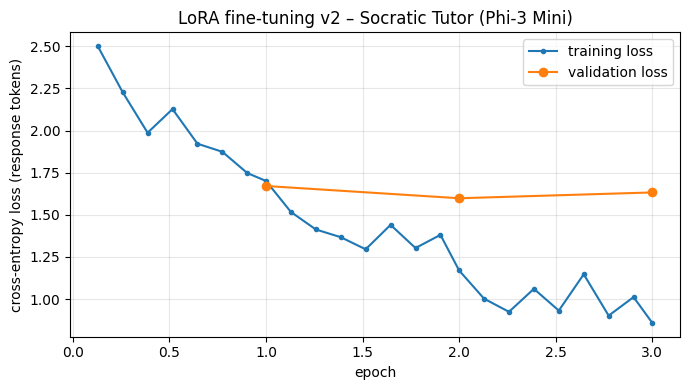

epoch 1: val loss 1.671
epoch 2: val loss 1.598
epoch 3: val loss 1.633


In [ ]:
import matplotlib.pyplot as plt

hist = trainer.state.log_history
tr = [(h["epoch"], h["loss"]) for h in hist if "loss" in h]
ev = [(h["epoch"], h["eval_loss"]) for h in hist if "eval_loss" in h]

plt.figure(figsize=(7, 4))
plt.plot(*zip(*tr), marker=".", label="training loss")
plt.plot(*zip(*ev), marker="o", label="validation loss")
plt.xlabel("epoch"); plt.ylabel("cross-entropy loss (response tokens)")
plt.title(f"LoRA fine-tuning {VERSION} – Socratic Tutor (Phi-3 Mini)")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/loss_curve.png", dpi=150)
plt.show()

for e, l in ev:
    print(f"epoch {e:.0f}: val loss {l:.3f}")

## 9. Save the adapter and the run settings
Only the LoRA adapter is saved (tens of MB, not the full 3.8B model).

In [ ]:
import transformers

trainer.model.save_pretrained(OUT_DIR)
tokenizer.save_pretrained(OUT_DIR)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
run_info = {
    "version": VERSION,
    "data": "54 original + 8 new examples; context = 2 retrieved non-quiz chunks (60 words) + original snippet",
    "base_model": MODEL_ID, "quantisation": "4-bit NF4 (QLoRA)",
    "lora": {"r": LORA_R, "alpha": LORA_ALPHA, "dropout": LORA_DROPOUT, "target_modules": "all-linear"},
    "epochs": EPOCHS, "learning_rate": LR, "warmup_steps": WARMUP_STEPS,
    "effective_batch": BATCH_SIZE * GRAD_ACCUM, "max_len": MAX_LEN,
    "train_examples": len(train_tok), "val_examples": len(val_tok),
    "trainable_params": trainable, "total_params": total,
    "train_minutes": round(train_minutes, 1),
    "peak_gpu_gb": round(torch.cuda.max_memory_allocated() / 1e9, 1),
    "final_train_loss": round(train_result.training_loss, 4),
    "val_loss_per_epoch": [round(l, 4) for _, l in ev],
    "system_role_supported": SYSTEM_SUPPORTED,
    "transformers_version": transformers.__version__,
    "gpu": torch.cuda.get_device_name(0),
}
json.dump(run_info, open(f"{OUT_DIR}/run_info.json", "w"), indent=1)
json.dump(hist, open(f"{OUT_DIR}/log_history.json", "w"), indent=1)
print("✅ Saved to", OUT_DIR)
print(os.listdir(OUT_DIR))

✅ Saved to /content/drive/MyDrive/CP5403_A2/models/socratic_lora_v2
['loss_curve.png', 'README.md', 'adapter_model.safetensors', 'adapter_config.json', 'chat_template.jinja', 'tokenizer_config.json', 'tokenizer.json', 'run_info.json', 'log_history.json', 'val_before_after.csv']


## 10. Quick before/after check (validation set)
The **same loaded model** is used twice: adapter **off** = base Phi-3, adapter **on** = fine-tuned.
This is only a sanity check; the full Baseline / RAG-only / Hybrid comparison is in `04_evaluation`.

In [ ]:
import pandas as pd
model.eval()
model.config.use_cache = True
tokenizer.padding_side = "left"

stop_ids = [tokenizer.eos_token_id]
end_id = tokenizer.convert_tokens_to_ids("<|end|>")
if isinstance(end_id, int) and end_id != tokenizer.unk_token_id:
    stop_ids.append(end_id)

@torch.no_grad()
def generate(msgs, max_new_tokens=200):
    prompt = tokenizer.apply_chat_template(prepare_messages(msgs), tokenize=False, add_generation_prompt=True)
    ids = tokenizer(prompt, return_tensors="pt", add_special_tokens=False).to(model.device)
    out = model.generate(**ids, max_new_tokens=max_new_tokens, do_sample=False,
                         eos_token_id=stop_ids, pad_token_id=tokenizer.pad_token_id)
    return tokenizer.decode(out[0, ids["input_ids"].shape[1]:], skip_special_tokens=True).strip()

rows = []
for r in val_raw:
    msgs = r["messages"][:-1]
    with model.disable_adapter():
        before = generate(msgs)
    after = generate(msgs)
    student = msgs[-1]["content"].split("[Student]")[-1].strip()
    rows.append({"id": r["id"], "category": r["category"], "student": student,
                 "before_base": before, "after_finetuned": after,
                 "target": r["messages"][-1]["content"],
                 "q_before": before.count("?"), "q_after": after.count("?"),
                 "words_before": len(before.split()), "words_after": len(after.split())})
    print(f"\n=== {r['id']} ({r['category']}) ===\nSTUDENT: {student}")
    print(f"\n[BEFORE] {before}\n\n[AFTER]  {after}")

df = pd.DataFrame(rows)
df.to_csv(f"{OUT_DIR}/val_before_after.csv", index=False)
print("\n", df[["id", "category", "q_before", "q_after", "words_before", "words_after"]])


=== S13 (opening) ===
STUDENT: Why use multi-head attention instead of one head?

[BEFORE] To understand why we use multi-head attention, let's consider the sentence you provided. Can you identify different elements in the sentence that might require separate focus for a comprehensive understanding?

[AFTER]  Imagine a single head only looking at the first word of a sentence. What would it miss about the rest of the sentence? Now apply that to a model with multiple heads: what does each head get to see, and how does that help the model?

=== S27 (followup_correct_misconception) ===
STUDENT: If training loss is very low, the model is great.

[BEFORE] To assess if your model is learning well, consider both training and validation losses. A very low training loss indicates the model is learning, but what about validation loss? Can you tell me what a rising validation loss might suggest about your model's performance?

[AFTER]  That's a common misconception. Training loss only tells you a

## 11. What to check, and notes for the report
**Good signs**
- Validation loss drops in epoch 1–2 and does not climb sharply in epoch 3
- `AFTER` replies are shorter, ask 1–2 questions and do not give the full answer
- S41 (direct-answer request) gives a hint, not the definition; S46 (stuck) uses a simpler example

**Warning signs → what to change**
| Symptom | Likely cause | Try |
|---|---|---|
| Val loss rises after epoch 1 | Overfitting on 54 examples | `EPOCHS = 2` or `LR = 1e-4` |
| AFTER looks the same as BEFORE | Too little training | `EPOCHS = 4` or `LORA_R = 32` |
| AFTER always asks questions, even for logistics | Over-learned the style | more `direct_ok` examples |
| CUDA out of memory | Long sequences | `MAX_LEN = 768`, restart runtime |

**Report sentences**
- *The model was fine-tuned with QLoRA (4-bit NF4 base, LoRA on all linear layers), so only a small fraction of parameters was updated (see `run_info.json`).*
- *Loss was computed on response tokens only; prompt tokens were masked, following the supervised instruction fine-tuning approach in Week 7.*
- *Training on 54 examples took X minutes on a single T4 GPU.*

**Next notebook:** `03_tutor_app.ipynb` (RAG retrieval + this adapter + multi-turn conversation).